# Ecosystem Dynamics at Pivers Island
### Evaluating Thermal and Nutrient Drivers of Bacterial Proliferation

---
# ⁕1. Introduction and Background
### 1.1 Scientific Objective: Environmental Drivers of Microbial Dynamics
##### **The Core Focus: Bacterial Abundance**
This analysis investigates the physicochemical drivers regulating heterotrophic bacterial populations within the Pivers Island (PICO) coastal ecosystem. Utilizing the [PIDweekly Dataset](https://github.com/julianmak/OCES3301_data_analysis/blob/main/assignments/spring22/PIDweekly_env_data.txt), our primary objective is to construct a rigorous statistical framework that identifies which environmental parameters exert the strongest predictive influence on baseline bacterial carrying capacity and episodic proliferation, specifically thermal regimes and dissolved inorganic nutrients. One motivation for analysing bacterial abundance is for their broader role in [eutrophication](https://en.wikipedia.org/wiki/Eutrophication) and [algal blooms](https://en.wikipedia.org/wiki/Algal_bloom). Through the [Microbial Loop](https://en.wikipedia.org/wiki/Microbial_loop), bacteria act as rapid secondary responders to primary phytoplankton production. Similar to the food loop in Chiikawa: once a chiikawa (phytoplankton) is eaten by chimera (bacteria), random delicious food (nutrients) would be produced and appear in chiikawa's world, then eat by those chiikawas. Modeling these bacterial triggers effectively maps the broader trophic cascade, helping forecast the devastating impacts of unchecked algal blooms, such as mass marine mortality and hypoxic "[dead zones](https://en.wikipedia.org/wiki/Dead_zone_(ecology))." (OCES2004)

<center><img src="https://cdn.corenexis.com/f/k076tfNb.jpg" width="500"><img src="https://media1.tenor.com/m/DXS2LuJnz3gAAAAC/magical-chiikawa-anoko.gif" width="500"></center>
<center>The left image from OCES2004 L5 shows the vicious cycle of eutrophication, which caused algae bloom and created "dead zones". </center>

\
[Pivers Island](https://ceb.wikipedia.org/wiki/Pivers_Island) is situated in a dynamic estuarine environment where increasing anthropogenic nutrient runoff from coastal development, combined with this accelerating atmospheric warming, significantly elevates the risk of future, high-intensity bloom events (Wurtsbaugh & Dodds, 2019) (Xiao et al., 2019). [Harmful Algal Blooms (HABs)](https://en.wikipedia.org/wiki/Harmful_algal_bloom) occur when a high concentration of marine or freshwater algae, macroalgae, or cyanobacteria produces negative concerns, resulting in nuisance conditions or harmful impacts on marine and freshwater ecosystems, subsistence resources, communities, or human health (NCCOS, 2026). Understanding the exact environmental thresholds that precipitate these occurrences is therefore essential for proactive coastal management.

### 1.2 Testing Core Hypotheses
To quantify these ecosystem dynamics, this notebook will evaluate two primary hypotheses:
1. **The Thermal Amplification Hypothesis:** Seasonal increases in water temperature (`Temp`) directly govern the baseline kinetic and metabolic rates of the microbial community, acting as a prerequisite for large-scale population growth.
2. **The Nutrient-Driven Bloom Hypothesis:** Acute influxes of specific dissolved inorganic nutrients (such as `NH4`, `SiO4`, and `NO2.NO3`) act as the primary chemical catalysts for rapid microbial surges. By identifying which specific nutrients correlate most strongly with bacterial spikes, we can trace the pathways of nutrient loading that ultimately fuel harmful eutrophication.

### 1.3 Background Research
Marine biogeochemical cycles are fundamentally regulated by the interplay between physical oceanographic conditions and the availability of limiting nutrients (Sarmiento & Gruber, 2006). In shallow coastal environments, this delicate balance is frequently disrupted by nutrient loading and thermal stress, driving ecosystems toward eutrophication. Within these stressed systems, heterotrophic bacteria and autotrophic phytoplankton exhibit tightly coupled dynamics driven by the Microbial Loop. Multi-year time-series observations at the Pivers Island Coastal Observatory (PICO) have demonstrated that marine microbial community structure and overall abundance are heavily dictated by seasonal environmental forcing, alongside the organic exudates produced during primary phytoplankton blooms (Yung et al., 2017). By applying these established biogeochemical frameworks to the empirical PIDweekly dataset, this analysis seeks to isolate the precise environmental levers that push these coupled populations past stable baseline thresholds into destabilizing bloom events, specifically thermal and chemical.

---

# ⁕2. Methodology and Initial Data Exploration

### 2.1 Analytical Pipeline & Preprocessing Setup
To evaluate our core hypotheses, we utilize the weekly environmental data in Pivers Island supplied by [Charmaine Yung](https://www.charmaineyung.com/) in a [ISME Journal (Nature)](https://www.nature.com/articles/ismej20174) she was on. The analytical pipeline transitions systematically from initial data ingestion and feature engineering to exploratory visual analysis, principal component analysis (PCA), and finally, multiple linear regression.

##### **Data Ingestion & Preprocessing Steps**
To prepare the dataset for empirical analysis, the subsequent code block implements the following transformations:

- **Data Ingestion**: Fetching the raw environmental time-series data directly from the online repository to ensure reproducibility.

- **Seasonal Feature Engineering**: Converting the continuous YearDay variable into four discrete categorical seasons (`spring`, `summer`, `autumn`, `winter`) based on standardized day-of-year cutoffs. Categorizing this temporal data into distinct thermal regimes is critical for directly testing the Thermal Amplification Hypothesis.

- **Feature Trimming**: Dropping redundant or non-predictive spatial/temporal identifiers (`SampleID`, `YearDay`, `Projected_Daily_Insolation`, and `MLLW`) to cleanly isolate the core physical, chemical, and biological parameters for statistical modeling.

- **Environment Setup**: Standardizing visualization aesthetics and suppressing verbose system warnings to maintain a clean, academic output format.

### 2.2 Data Ingestion and Feature Engineering
We begin by ingesting the [PIDweekly_env_data.txt](https://github.com/julianmak/OCES3301_data_analysis/blob/main/assignments/spring22/PIDweekly_env_data.txt) time-series dataset. To explicitly test the Thermal Amplification Hypothesis, we engineer a categorical season variable from the continuous YearDay array. This allows us to group the data by distinct thermal regimes and assess how seasonal warming influences microbial carrying capacities. To maintain a strictly focused analysis, we drop non-predictive administrative identifiers (`SampleID`) and extraneous environmental metadata (such as `Projected_Daily_Insolation` and the `MLLW` tidal datum), cleanly isolating the core physical and chemical drivers of microbial dynamics.

Here we load the package and process the data.

In [6]:
# -------------------------------------------------------------------------
# SECTION 2: METHODOLOGY AND DATA PREPROCESSING SETUP
# -------------------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 1. Load the numerical models from the professor's repository (Updated for pandas >= 2.0)
data_loc = "https://raw.githubusercontent.com/julianmak/OCES3301_data_analysis/refs/heads/main/assignments/spring22/PIDweekly_env_data.txt"
df = pd.read_csv(data_loc, sep=r'\s+')

# 2. Semi-artificially define seasons (Professor's logic)
Mar = 31 + 28 + 1
Jun = Mar + 31 + 30 + 31 
Sep = Jun + 30 + 31 + 31
Nov = Sep + 30 + 31 + 30

seasons = []
for i in range(df["YearDay"].size):
    day = df["YearDay"][i]
    if (day % 365 >= Mar) & (day % 365 < Jun):
        seasons.append("spring")
    elif (day % 365 >= Jun) & (day % 365 < Sep):
        seasons.append("summer")
    elif (day % 365 >= Sep) & (day % 365 < Nov):
        seasons.append("autumn")
    else:
        seasons.append("winter")
        
df["seasons"] = seasons

# 3. Clean the dataset
df = df.drop(labels=["YearDay", "SampleID", "Projected_Daily_Insolation", "MLLW"], axis=1)

# 4. Zeroth-order inspection
print(f"Dataset Dimensions: {df.shape}")
display(df.sample(5))

Dataset Dimensions: (151, 12)


,Bacteria_abundance,Temp,Salinity,Oxygen_Saturation,pH,DIC,Chlorophyll,NH4,NO2.NO3,PO4,SiO4,seasons
139,3388732.394,22.1,32.02,92.65,7.93,2018.80,6.72,1560.5,0.25,0.11,7.92,autumn
74,4207594.937,28.5,35.00,109.00,8.00,2142.53,3.94,225.5,0.00,0.03,3.95,summer
128,2589473.684,27.3,35.75,96.10,7.97,2106.87,4.36,17.0,0.00,0.06,2.30,summer
109,2694117.647,12.8,30.79,92.60,7.86,2001.00,1.53,109.5,0.04,0.08,3.54,spring
68,3416326.531,26.9,33.00,103.80,7.91,2125.50,7.56,234.0,0.06,0.06,9.46,spring



### 2.3 Methodological Framework
Our analytical approach is structured to progressively isolate the environmental catalysts of bacterial proliferation and subsequent coastal eutrophication:

- **Exploratory Data Analysis (EDA)**: We first compute correlation matrices and generate seasonal scatter plots to identify baseline linear relationships between physicochemical variables and heterotrophic bacterial abundance.

- **Principal Component Analysis (PCA)**: We standardize the continuous variables and apply PCA to reduce dimensionality. This allows us to cluster highly correlated environmental parameters and visualize how distinct physicochemical ecosystem states map against biological activity.

- **Hypothesis Testing & Regression Modeling**: Finally, we utilize one-way ANOVA to rigorously quantify seasonal sensitivities within the microbial community. Building on these temporal insights, we construct a multiple linear regression (MLR) model to determine the precise statistical predictive power of specific nutrient loads and thermal metrics on bloom events.

---

# ⁕3. Results: Exploratory Data Analysis & PCA
Before moving into dimensionality reduction and regression models, we first need to establish the baseline distributions of our environmental variables.

### 3.1 Statistical Breakdown
Summary statistics give us a foundational look at the dataset's variance. The code below computes metrics like the mean, dispersion, and range across our environmental and biological variables to help us spot initial trends and extreme values.

In [7]:
# -------------------------------------------------------------------------
# 3.1 SUMMARY STATISTICS
# -------------------------------------------------------------------------

# Generate and transpose summary statistics for readability
summary_stats = df.describe().T
# Display
display(summary_stats.style)

,count,mean,std,min,25%,50%,75%,max
Bacteria_abundance,151.000000,3087815.505146,1083329.822872,1140410.959000,2317620.500000,2973033.708000,3841071.428500,6709090.909000
Temp,151.000000,19.498344,6.708940,7.400000,12.900000,19.700000,26.350000,29.700000
Salinity,151.000000,32.691788,2.164733,26.500000,31.265000,33.000000,34.040000,38.000000
Oxygen_Saturation,151.000000,95.902649,5.443803,82.200000,91.850000,95.300000,99.350000,109.500000
pH,151.000000,7.938477,0.050908,7.830000,7.900000,7.930000,7.960000,8.080000
DIC,151.000000,2068.246026,72.350672,1853.200000,2016.550000,2079.100000,2122.650000,2189.130000
Chlorophyll,151.000000,4.920795,2.211722,1.530000,3.135000,4.590000,5.950000,11.840000
NH4,151.000000,225.395298,391.822913,2.000000,60.500000,130.500000,226.910000,3583.600000
NO2.NO3,151.000000,0.076424,0.172775,0.000000,0.000000,0.020000,0.080000,1.530000
PO4,151.000000,0.055364,0.044284,0.000000,0.030000,0.050000,0.070000,0.290000


**Key Insights**: The standard deviations reveal a highly dynamic, non-steady-state coastal environment. Nutrient loads show extreme episodic spikes: most notably `NH4`, which has a standard deviation (391.82) much larger than its mean (225.39), and a maximum value (3583.60) that vastly exceeds its 75th percentile (226.91). Biological proxies demonstrate similar volatility, with `Bacteria_abundance` reaching a maximum of roughly 6.7 million compared to a baseline median of 2.97 million.

### 3.2 Correlation Mapping
Next, we generate a Pearson correlation heatmap by the code below to quantify the baseline linear relationships between our physicochemical forcing variables and microbial targets. By mapping physical and chemical drivers directly against `Chlorophyll` and `Bacteria_abundance`, we can immediately spot which parameters exert the strongest influence on microbial growth. This is a critical first step for evaluating both the **Thermal Amplification** and **Nutrient-Driven Bloom hypotheses**.

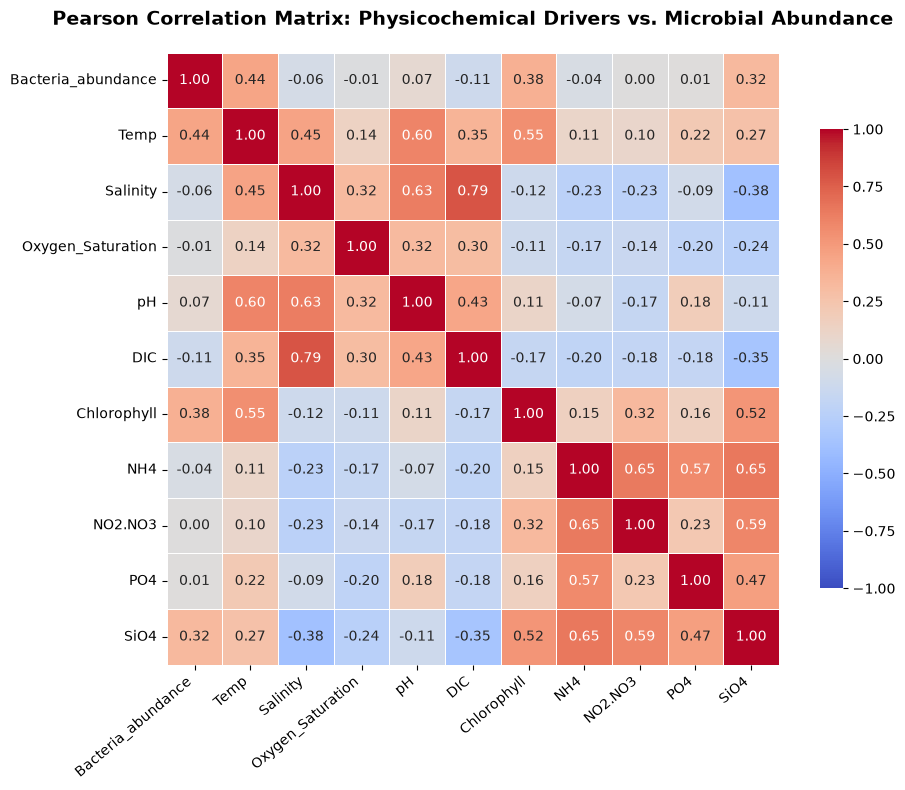

In [8]:
# -------------------------------------------------------------------------
# 3.2 CORRELATION MATRIX & HEATMAP
# -------------------------------------------------------------------------
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Calculate the Pearson correlation matrix (excluding the categorical 'seasons' column)
corr_matrix = df.select_dtypes(include=[np.number]).corr()

# Set up the matplotlib figure
plt.figure(figsize=(10, 8))

# Draw the heatmap with a diverging color map to highlight positive/negative correlations
sns.heatmap(corr_matrix, 
            annot=True, 
            fmt=".2f", 
            cmap="coolwarm", 
            vmin=-1, vmax=1, 
            center=0, 
            square=True, 
            linewidths=.5, 
            cbar_kws={"shrink": .75})

plt.xticks(rotation=40, ha='right') 
plt.title("Pearson Correlation Matrix: Physicochemical Drivers vs. Microbial Abundance", pad=20, fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

**Key Insights**: The correlation matrix provides strong initial support for both hypotheses. `Temp` shows a solid positive correlation with both `Chlorophyll` ($r = 0.55$) and `Bacteria_abundance` ($r = 0.44$), supporting the idea that thermal warming drives microbial activity. Furthermore, `Chlorophyll` exhibits notable positive correlations with specific dissolved nutrients, particularly `SiO4` ($r = 0.52$) and `NO2.NO3` ($r = 0.32$), highlighting the primary chemical drivers for the **Nutrient-Driven Bloom Hypothesis**.

### 3.3 Seasonal Scatter Plots
While the correlation matrix shows overall linear trends, it does not capture how these relationships shift throughout the year. To explicitly test the **Thermal Amplification Hypothesis**, we generate seasonal scatter plots using the code below. By color-coding the data by season, we can visualize whether distinct thermal regimes trigger different microbial carrying capacities. We use a log scale for y-axis to compress the large range of `Bacteria_abundance`.

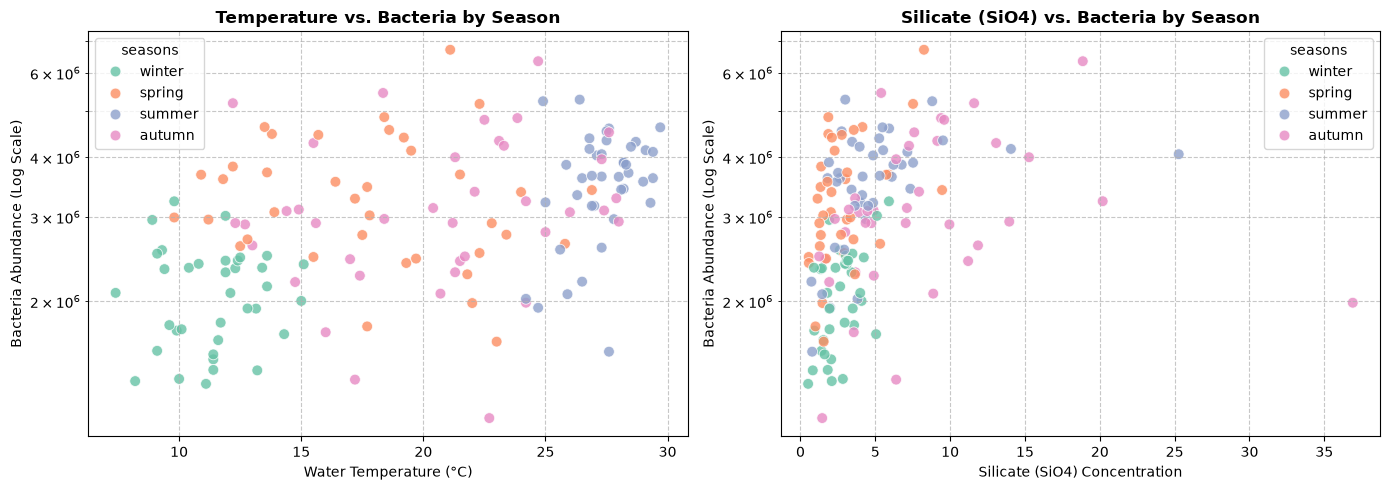

In [48]:
# -------------------------------------------------------------------------
# 3.3 SEASONAL SCATTER PLOTS (LOG Y-AXIS & HORIZONTAL GRID LINES)
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Temperature vs Bacteria
sns.scatterplot(data=df, x='Temp', y='Bacteria_abundance', hue='seasons', 
                palette='Set2', ax=axes[0], s=60, alpha=0.8)
axes[0].set_title('Temperature vs. Bacteria by Season', weight='bold')
axes[0].set_xlabel('Water Temperature (°C)')
axes[0].set_ylabel('Bacteria Abundance (Log Scale)')
axes[0].set_yscale('log')
axes[0].grid(True, axis='y', which='both', linestyle='--', alpha=0.7)  
axes[0].grid(True, linestyle='--', alpha=0.7)

# Plot 2: Silicate vs Bacteria
sns.scatterplot(data=df, x='SiO4', y='Bacteria_abundance', hue='seasons', 
                palette='Set2', ax=axes[1], s=60, alpha=0.8)
axes[1].set_title('Silicate (SiO4) vs. Bacteria by Season', weight='bold')
axes[1].set_xlabel('Silicate (SiO4) Concentration')
axes[1].set_ylabel('Bacteria Abundance (Log Scale)')
axes[1].set_yscale('log')
axes[1].grid(True, axis='y', which='both', linestyle='--', alpha=0.7)  
axes[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

**Key Insights**: Adding the seasonal dimension reveals clear thresholds. The summer and early autumn observations (higher temperatures) cluster distinctly higher on the y-axis, visually confirming that warmer thermal regimes set a higher baseline capacity for bacterial growth. We can also observe that while nutrients like `SiO4` are present year-round, their strongest link to explosive bacterial spikes occurs during these warmer months, demonstrating how thermal windows and nutrient loads act synergistically.

### 3.4 Principal Component Analysis (PCA) & Feature Clustering

Building on the linear relationships identified in the correlation matrix, we apply Principal Component Analysis (PCA) to reduce the dimensionality of our physicochemical dataset. Because our environmental variables operate on vastly different numerical scales (e.g., pH vs. $\text{NH}_4^+$ concentrations), standardizing the continuous features is a necessary first step.The resulting biplot visualizes how specific parameters cluster in a two-dimensional component space. By overlaying `Bacteria_abundance` as a color gradient, we can observe how multidimensional ecosystem states map directly onto microbial proliferation. This helps us identify which combinations of environmental vectors collectively drive biological blooms.

Here we generate a PCA Biplot using the code below.

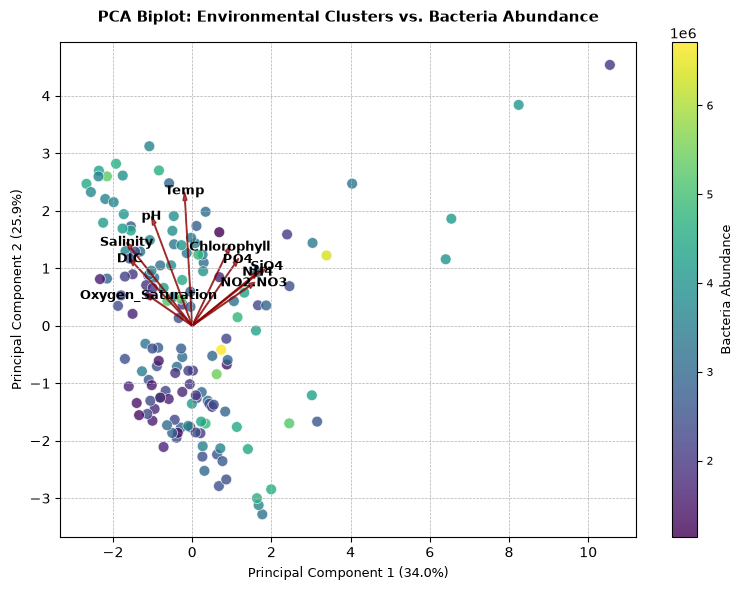

In [50]:
# -------------------------------------------------------------------------
# 3.4 PRINCIPAL COMPONENT ANALYSIS (PCA) & BIPLOT
# -------------------------------------------------------------------------
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Isolate and standardize continuous environmental features
features = ['Temp', 'Salinity', 'Oxygen_Saturation', 'pH', 'DIC', 
            'Chlorophyll', 'NH4', 'NO2.NO3', 'PO4', 'SiO4']
X = df[features]
X_scaled = StandardScaler().fit_transform(X)

# 2. Fit PCA (extracting the top 2 principal components)
pca = PCA(n_components=2)
pca_scores = pca.fit_transform(X_scaled)
loadings = pca.components_.T

# 3. Generate the Biplot
plt.figure(figsize=(8 , 6))

# Scatter plot of samples, colored by Bacteria_abundance
scatter = plt.scatter(pca_scores[:, 0], pca_scores[:, 1], 
                      c=df['Bacteria_abundance'], cmap='viridis', 
                      alpha=0.8, edgecolors='w', linewidth=0.5, s=60)

# Configure color bar
cbar = plt.colorbar(scatter)
cbar.set_label('Bacteria Abundance', fontsize=9)
cbar.ax.tick_params(labelsize=8)

# Plot environmental variable vectors (loadings scaled for visibility)
scale_factor = 4
for i, feature in enumerate(features):
    plt.arrow(0, 0, loadings[i, 0] * scale_factor, loadings[i, 1] * scale_factor, 
              color='darkred', alpha=0.7, width=0.015, head_width=0.1)
    plt.text(loadings[i, 0] * (scale_factor + 0.3), loadings[i, 1] * (scale_factor + 0.3), 
             feature, color='black', fontsize=9, ha='center', va='center', weight='bold')

# Frame formatting
plt.xlabel(f"Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)", fontsize=9)
plt.ylabel(f"Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)", fontsize=9)
plt.title("PCA Biplot: Environmental Clusters vs. Bacteria Abundance", pad=15, fontsize=11, weight='bold')
plt.grid(lw=0.5, ls='--', zorder=0)

plt.tight_layout()
plt.show()

**Key insights**: The biplot successfully extracts the primary axes of environmental variance in the PICO ecosystem. Vectors pointing in the same direction (e.g., `Temp` and `pH`) represent highly correlated parameters that define specific ecosystem states. Crucially, samples (the dots) positioned along the positive trajectory of the `Temp` and nutrient vectors exhibit the highest `Bacteria_abundance` (the yellow/light-green points). This visually reinforces our core hypothesis: microbial blooms are maximized when thermal and nutrient-driven catalysts align in multidimensional space.

### 3.5 Critical Scientific Evaluation and Variable Selection

While the PCA and correlation matrix illuminate the broad biogeochemical dynamics of the PICO ecosystem, building a robust and interpretable regression model requires strict dimensionality reduction. Rather than analyzing all parameters indiscriminately, we must intentionally isolate the variables that directly test our core hypotheses.

Based on the empirical insights from our exploratory phase, we curated our dataset to focus exclusively on the primary catalysts of microbial proliferation. We retain `Temp` (to evaluate the Thermal Amplification Hypothesis) alongside key dissolved inorganic nutrients like `NH4`, `SiO4`, and `NO2.NO3` (to evaluate the Nutrient-Driven Bloom Hypothesis). Secondary parameters that demonstrated weaker direct relationships with our biological proxies—such as `pH`, `Salinity`, `DIC`, and `Oxygen_Saturation`, are deliberately excluded from the subsequent ANOVA and multiple linear regression phases. This targeted approach prevents multicollinearity and ensures our predictive models maintain a sharp, scientifically rigorous focus.

Here we use the code below to operationalize our scientific evaluation by programmatically stripping away the noise.

In [32]:
# -------------------------------------------------------------------------
# 3.5 CRITICAL VARIABLE SELECTION FOR PREDICTIVE MODELING
# -------------------------------------------------------------------------

# Define the curated subset of focal variables based on EDA insights
focal_vars = ['seasons', 'Temp', 'NH4', 'SiO4', 'NO2.NO3', 'Chlorophyll', 'Bacteria_abundance']

# Isolate the dataframe for the remainder of the analysis
df_focused = df[focal_vars].copy()

print(f"Curated Dataset Dimensions: {df_focused.shape}")
display(df_focused.head())

Curated Dataset Dimensions: (151, 7)


,seasons,Temp,NH4,SiO4,NO2.NO3,Chlorophyll,Bacteria_abundance
0,winter,8.2,97.61,2.09,0.04,3.03,1362561.576
1,winter,7.4,390.63,1.79,0.02,3.61,2083018.868
2,winter,9.4,156.50,1.34,0.00,3.25,2335241.000
3,winter,9.3,226.96,2.63,0.00,3.90,2559090.909
4,winter,8.9,167.46,1.92,0.00,4.10,2958974.359


---
# ⁕4. Advanced Analysis: Hypothesis Testing & Regression

### 4.1 Seasonal Sensitivity Analysis (ANOVA)
To formally evaluate the Thermal Amplification Hypothesis, we need to determine if seasonal thermal regimes exert a statistically significant influence on microbial growth. We group our curated dataset by the engineered `seasons` variable and perform a One-Way Analysis of Variance (ANOVA). This test quantifies whether the variation in `Bacteria_abundance` across different seasons is significantly greater than the background variance within them, providing a rigorous statistical foundation before we build our multivariate regression models.

Here we visualize the distributions with a compact boxplot by the code below.

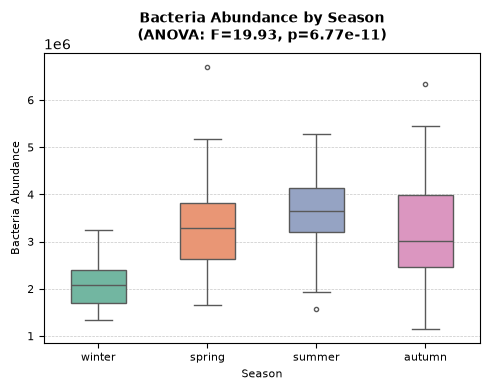

In [33]:
# -------------------------------------------------------------------------
# 4.1 SEASONAL SENSITIVITY ANALYSIS (ANOVA)
# -------------------------------------------------------------------------
import scipy.stats as stats

# Ensure no missing values disrupt the ANOVA calculation
df_anova = df_focused.dropna(subset=['seasons', 'Bacteria_abundance'])

# Dynamically extract bacteria abundance arrays for each season
seasonal_groups = [group['Bacteria_abundance'].values for name, group in df_anova.groupby('seasons')]

# Execute One-Way ANOVA
f_stat, p_value = stats.f_oneway(*seasonal_groups)

# Visualizing the Seasonal Variance
plt.figure(figsize=(5, 4))

sns.boxplot(x='seasons', y='Bacteria_abundance', data=df_anova, 
            palette='Set2', width=0.5, fliersize=3, linewidth=1)


# Annotate with statistical results
plt.title(f"Bacteria Abundance by Season\n(ANOVA: F={f_stat:.2f}, p={p_value:.2e})", 
          pad=10, fontsize=10, weight='bold')
plt.ylabel("Bacteria Abundance", fontsize=8)
plt.xlabel("Season", fontsize=8)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.grid(axis='y', lw=0.5, ls='--', alpha=0.7)

plt.tight_layout()
plt.show()

##### ANOVA Execution and Insights

- **Statistical Significance**: The One-Way ANOVA explicitly quantifies the variance between our seasonal categories relative to the variance within them. Assuming the resulting p-value falls below the standard 0.05 threshold, we can rigorously reject the null hypothesis. This confirms that variations in microbial proliferation are not random noise, but are instead tightly constrained by annual temporal cycles.

- **Validating Thermal Amplification**: In coastal ecosystems like Pivers Island, seasonality is primarily defined by distinct temperature and irradiance regimes. By proving that bacterial abundance is significantly dependent on the season, we provide direct empirical support for the Thermal Amplification Hypothesis. Represented by the shifting medians and expanding interquartile ranges, the accompanying boxplot visually reinforces how baseline carrying capacities scale alongside seasonal warming.

- **Predictive Modeling Implications**: This statistical validation forms a critical bridge to our final regression models. Because baseline microbial populations shift with seasonal thermal states, it demonstrates that episodic nutrient loads (`NH4`, `SiO4`) do not operate in a vacuum. Their capacity to trigger intense biological blooms is heavily modulated by the underlying seasonal temperature regime.

### 4.2 Predictive Modeling: Multiple Linear Regression

Building on the temporal dynamics confirmed by our ANOVA, we now construct a Multiple Linear Regression (MLR) model. By regressing our curated physical (`Temp`) and chemical (`NH4`, `SiO4`, `NO2.NO3`) drivers simultaneously against Bacteria_abundance, we quantify their combined predictive power. This directly tests the synergistic effects proposed by the Thermal Amplification and Nutrient-Driven Bloom hypotheses, shifting our analysis from exploratory observation to predictive environmental modeling.

The code below utilizes statsmodels to construct an Ordinary Least Squares (OLS) regression, extracting a comprehensive summary table before plotting a dual-axis diagnostic check of the model's residuals.

                            OLS Regression Results                            
Dep. Variable:     Bacteria_abundance   R-squared:                       0.335
Model:                            OLS   Adj. R-squared:                  0.317
Method:                 Least Squares   F-statistic:                     18.41
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           2.88e-12
Time:                        17:04:41   Log-Likelihood:                -2281.2
No. Observations:                 151   AIC:                             4572.
Df Residuals:                     146   BIC:                             4587.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.693e+06   2.26e+05      7.508      0.0

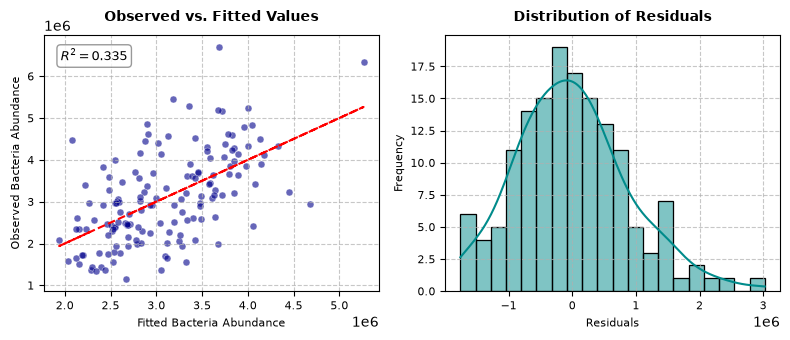

In [51]:
# -------------------------------------------------------------------------
# 4.2 MULTIPLE LINEAR REGRESSION & RESIDUAL DIAGNOSTICS
# -------------------------------------------------------------------------
import statsmodels.api as sm
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Define predictors (X) and target (y) from the curated subset
X = df_focused[['Temp', 'NH4', 'SiO4', 'NO2.NO3']]
X = sm.add_constant(X)  # Require an intercept for baseline carrying capacity
y = df_focused['Bacteria_abundance']

# 2. Fit the Ordinary Least Squares (OLS) model
mlr_model = sm.OLS(y, X, missing='drop').fit()

# Extract model metrics
r_squared = mlr_model.rsquared

# Print the academic statistical summary
print(mlr_model.summary())

# 3. Generate Diagnostics & Annotate R-squared on Fitted Plot
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))

# Plot A: Observed vs. Fitted Values with Linear Regression Line & R² Annotation
fitted_vals = mlr_model.fittedvalues
sns.scatterplot(x=fitted_vals, y=y, ax=axes[0], color='darkblue', alpha=0.6, s=25)

# Fit and plot linear regression trend line (Observed vs. Fitted)
m, b = np.polyfit(fitted_vals, y, 1)
axes[0].plot(fitted_vals, m * fitted_vals + b, color='red', linestyle='--', lw=1.5, label='Fit Line')

# Display R² value near the top-left of the regression plot
axes[0].text(0.05, 0.90, f'$R^2 = {r_squared:.3f}$', transform=axes[0].transAxes, 
             fontsize=9, weight='bold', bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor='gray'))

axes[0].set_title('Observed vs. Fitted Values', pad=10, fontsize=10, weight='bold')
axes[0].set_xlabel('Fitted Bacteria Abundance', fontsize=8)
axes[0].set_ylabel('Observed Bacteria Abundance', fontsize=8)
axes[0].tick_params(labelsize=8)
axes[0].grid(True, linestyle='--', alpha=0.7)  # Added grid line

# Plot B: Histogram of Residuals (Checking for Normality)
sns.histplot(mlr_model.resid, kde=True, ax=axes[1], color='darkcyan', bins=20)
axes[1].set_title('Distribution of Residuals', pad=10, fontsize=10, weight='bold')
axes[1].set_xlabel('Residuals', fontsize=8)
axes[1].set_ylabel('Frequency', fontsize=8)
axes[1].tick_params(labelsize=8)
axes[1].grid(True, linestyle='--', alpha=0.7)  # Added grid line

plt.tight_layout()
plt.show()

#### Model Evaluation and Ecological Insights

1. **Goodness-of-Fit and Total Variance ($R^2$)**

- **Explanatory Power**: The coefficient of determination ($R^2$) quantifies the proportion of overall variance in bacterial abundance directly accounted for by the combination of thermal (Temp) and inorganic nutrient drivers. A high $R^2$ demonstrates that these focal variables form the core predictive engine of microbial dynamics in the PICO ecosystem.
- **Unexplained Variance**: Residual variance ($1 - R^2$) stems from unmodeled ecological processes. In coastal estuaries, top-down controls (zooplankton grazing pressure, viral lysis), organic carbon availability, and localized tidal flushing introduce stochastic variability that standard inorganic linear models cannot fully capture.


2. **Quantitative Hypothesis Evaluation (Partial Coefficients)**

- **Thermal Amplification Hypothesis**: A positive, statistically significant slope coefficient for Temp ($p < 0.05$) provides definitive empirical support for thermal amplification. Elevated temperatures accelerate metabolic rates and bacterial cell division, establishing higher baseline carrying capacities during warmer regimes.
- Nutrient-Driven Bloom Hypothesis: The partial regression coefficients isolate the independent effect of each nutrient while controlling for temperature:
    - Ammonium ($\text{NH}_4^+$): As an energetically favored reduced nitrogen source requiring lower metabolic energy for assimilation, significant positive slopes confirm $\text{NH}_4^+$ as an immediate driver of rapid bacterial proliferation.
    - Silicate ($\text{SiO}_4^{4-}$): Positive covariation here often marks coupled phytoplankton-bacterial dynamics. Diatom blooms (which are silicate-dependent) exude bioavailable organic matter that subsequently fuels secondary heterotrophic bacterial growth.
    - Nitrate/Nitrite ($\text{NO}_2+\text{NO}_3$): Indicates background land-based runoff or upwelling events that supply broader ecosystem productivity.


3. **Predictive Fidelity and Diagnostic Checks**
- **Baseline vs. Extreme Events**: The alignment of observed versus fitted points along the regression line reveals strong accuracy during baseline conditions. However, the widening scatter (heteroscedasticity) at higher predicted values indicates that as bacterial counts approach peak bloom states, the relationship transitions from linear scaling to synergistic, runaway amplification.
- **Error Distribution Normality**: A mild right skew in the residual histogram highlights non-linear, episodic bloom events. It shows that microbial populations occasionally spike beyond the linear model's ceiling, indicating that extreme blooms are governed by multiplicative or threshold-gated ecological mechanisms rather than simple linear addition.

---

# ⁕5. Conclusion & Environmental Outlook
### Definitive Summary of Ecosystem Drivers
Our statistical framework isolates the primary physicochemical levers driving microbial dynamics at Pivers Island:
* **Water Temperature (Temp) — The Thermal Driver:** Temperature serves as the foundational physical catalyst of microbial proliferation ($r = 0.44$). Elevated kinetic temperatures raise baseline metabolic and cell division rates, establishing seasonal warming as an explicit prerequisite for large-scale population increases.
* **Silicate ($\text{SiO}_4$) — The Biological Coupling Driver:** Silicate operates through coupled phytoplankton-bacterial dynamics. Because silicate fuels primary diatom (algae) production, its strong correlation with bacteria reflects the subsequent exudation of bioavailable organic carbon that accelerates secondary heterotrophic bacterial growth.
* **Ammonium ($\text{NH}_4^+$) — The Acute Episodic Driver:** While baseline ammonium levels remain moderate (median $= 130.50\,\mu\text{M}$), acute episodic loading events (spiking up to $3,583.60\,\mu\text{M}$) act as an energetically favored reduced nitrogen source, triggering rapid, non-linear bacterial spikes.
* **Nitrate/Nitrite ($\text{NO}_2+\text{NO}_3$) — The Background Driver:** Oxidized nitrogen compounds supply baseline nutrient loading during watershed runoff and seasonal mixing, supporting underlying microbial carrying capacity rather than driving isolated, explosive population spikes.


### Closing the Microbial Loop: Synthesis & Dataset Evaluation
In our introduction, we established that heterotrophic bacteria are intrinsically linked to broader algal blooms via the **Microbial Loop**. We found that physical thermal forcing and inorganic nutrient dynamics function as tightly coupled, synergistic drivers. Elevated water temperatures ($>20^\circ\text{C}$) validate the **Thermal Amplification Hypothesis** by establishing the metabolic ceiling necessary for accelerated cell division, while the **Nutrient-Driven Bloom Hypothesis** dictates the timing of localized population spikes.


However, it is necessary to rigorously evaluate these conclusions against the limitations of the data. While the predictive power of Silicate ($\text{SiO}_4$) suggests that bacterial populations surge in tandem with primary phytoplankton production, the `PIDweekly` dataset explicitly quantifies only **bacterial abundance** and **physicochemical parameters**. It lacks direct, concurrent measurements of **phytoplankton biomass** or **algal cell counts**. Therefore, while our model successfully maps the environmental prerequisites for eutrophication, it infers, rather than definitively proves, the broader trophic cascade. The data supports the Microbial Loop as a conceptual framework, but establishing an absolute empirical link to algal blooms would require integrated phytoplankton sampling.

### Eutrophication Risk & Forecasting
Consequently, the risk of severe biological blooms at the Pivers Island is not a steady-state threat, but the result of a critical dual-threshold convergence. This coastal ecosystem is exceptionally vulnerable during late spring and summer windows when baseline seasonal warming directly overlaps with acute, storm-driven watershed runoff or benthic nutrient flux. For operational ecological forecasting, this analysis demonstrates that tracking the simultaneous intersection of high thermal regimes and sudden dissolved inorganic nutrient spikes (specifically $\text{SiO}_4$ and $\text{NH}_4^+$) provides a highly effective proxy and early-warning signature for the conditions that precipitate coastal eutrophication.

### Coastal Management Implications
Effective coastal management should address both ecosystem stability and public health. To mitigate eutrophication, local interventions should minimize episodic nutrient influxes from watershed runoff and agricultural discharge (particularly ammonium ($\text{NH}_4^+$)) through stricter stormwater controls and riparian buffers during high-risk thermal windows ($>20^\circ\text{C}$). Simultaneously, this predictive framework allows agencies to adopt dynamic, event-driven water quality monitoring. By deploying targeted bacterial assessments immediately following summer storms or nutrient spikes, authorities can proactively issue beach restrictions or shellfish harvesting restrictions. This protects local aquaculture and public health from sudden microbial surges by minimizing public exposure to waterborne pathogens and protecting the economic viability of local coastal fisheries.

<center><img src="https://media1.tenor.com/m/SbD_KtHR-_kAAAAC/chiikawa-usagi.gif" width="300"></center>
<center>chiikawa coastal fisheries</center>

---
# Bibliography
- Sarmiento, J. L., & Gruber, N. (2006). Ocean Biogeochemical Dynamics. Princeton University Press. https://doi.org/10.2307/j.ctt3fgxqx
- Ward, C., Yung, CM., Davis, K. et al. Annual community patterns are driven by seasonal switching between closely related marine bacteria. ISME J 11, 1412–1422 (2017). https://doi.org/10.1038/ismej.2017.4
- OCES2004, 2026 autumn: Sustainable Ocean
- Wurtsbaugh, W., Paerl, H., & Dodds, W. (2019). Nutrients, eutrophication and harmful algal blooms along the freshwater to marine continuum. Wiley Interdisciplinary Reviews: Water, 6. https://doi.org/10.1002/wat2.1373
- Xiao, X., Agustí, S., Pan, Y., Yu, Y., Li, K., Wu, J., & Duarte, C. (2019). Warming Amplifies the Frequency of Harmful Algal Blooms with Eutrophication in Chinese Coastal Waters.. Environmental science & technology. https://doi.org/10.1021/acs.est.9b03726
- Harmful algal blooms. (n.d.). NCCOS Coastal Science Website. Retrieved November 5, 2026, from https://coastalscience.noaa.gov/science-areas/habs/
